# 03 · Yields + macro (Diebold–Rudebusch–Aruoba), USD

Notebooks 01–02 forecast the curve from the curve alone. Out of sample they
do not beat the random walk significantly at h = 6, 12, and no yields-only
model beats the forward curve (README §7.4). This notebook asks whether
**macro information** changes that, with the model of Diebold, Rudebusch &
Aruoba (2006) (README §6.4):

$$
x_t = (L_t, S_t, C_t, \mathrm{CU}_t, \pi_t, i_t)', \qquad x_t - \mu = A (x_{t-1} - \mu) + \eta_t,
$$

where the three Nelson–Siegel factors are latent and capacity utilisation
(CU), core PCE inflation (π) and the fed funds rate (i) are observed without
error. The yields load on the factors only, so the macro variables reach the
curve through A and Q.

1. **Real-time data:** what a forecaster knew at each date, and how much it
   was later revised.
2. **Full-sample estimates:** the 6×6 VAR matrix A, with standard errors.
3. **Impulse responses:** do macro shocks move the curve, and does the curve
   move the macro variables? With 90% bands from parameter uncertainty.
4. **Variance decompositions.**
5. **Policy-rate-only model:** the parsimonious version that forecasts best.
6. **Out of sample:** macro vs yields-only (Clark–West), and vs the forward
   curve (Diebold–Mariano), using real-time macro data.

Sections 2–5 are in-sample and use the latest data vintage. They describe
the joint dynamics; they are not forecasts. Section 6 uses only what was
known at each origin.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from yck.data.realtime import RealTimeMacro
from yck.model.dns import ns_loadings, maturities_from_columns
from yck.model.statespace_dns import fit_dns_mle
from yck.model import irf
from yck.eval.backtest import random_walk_forecasts, forward_forecasts
from yck.eval.grid import ensure_results
from yck.eval.stats import clark_west, dm_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "data/results"
CONFIG = ROOT / "config/data_sources.yaml"
EST_START, FIRST_ORIGIN, H = "1985-01-31", "2000-01-31", (1, 6, 12)
MACRO = ["real_activity", "inflation", "policy_rate"]
LABEL = {"level": "level", "slope": "slope", "curvature": "curvature",
         "real_activity": "capacity util.", "inflation": "inflation", "policy_rate": "fed funds"}

y = pd.read_parquet(ROOT / "data/processed/curves_USD.parquet").loc[EST_START:]
macro_latest = pd.read_parquet(ROOT / "data/processed/macro_USD.parquet")
data = y.join(macro_latest[MACRO], how="left")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(y)} months, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}")
data[MACRO].describe().round(2)

502 months, 1985-01 to 2026-10


,real_activity,inflation,policy_rate
count,501.00,501.00,502.00
mean,78.78,2.40,3.47
std,3.61,1.31,2.70
min,64.08,-1.47,0.05
25%,76.45,1.57,0.69
50%,78.70,2.27,3.63
75%,81.34,3.03,5.45
max,85.19,7.22,9.85


## 1. Real-time macro data

Capacity utilisation and PCE inflation are published with a lag and then
revised, sometimes years later. A backtest that uses today's vintage
gives the model information nobody had (look-ahead bias). The backtests
in §6 therefore use, at every origin, the series exactly as published on
that date (ALFRED vintages), with unreleased months left missing for the
Kalman filter (README §7.3).

How big are the revisions? For each month since 2000, the latest observation
known at the end of that month (usually two months earlier) is compared with
its value in today's vintage.

,mean revision,sd,max |revision|,mean lag (months)
var,,,,
inflation,0.07,0.24,1.14,1.23
real_activity,-0.43,1.08,2.77,1.01


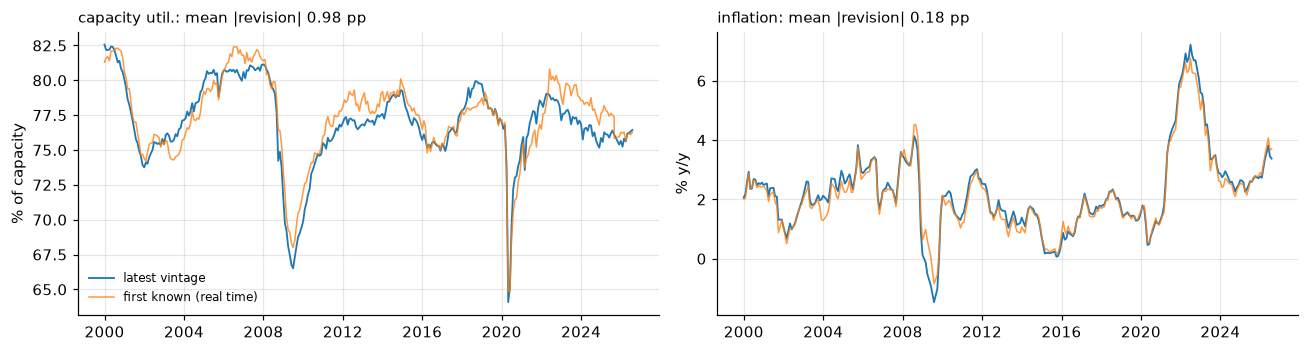

In [2]:
rt = RealTimeMacro.load("USD", ROOT / "data", CONFIG)
rows = []
for t in pd.date_range(FIRST_ORIGIN, macro_latest.index[-3], freq="ME"):
    known = rt.at(t)
    for var in ("real_activity", "inflation"):
        s = known[var].dropna()
        rows.append({"origin": t, "var": var, "month": s.index[-1], "real_time": s.iloc[-1],
                     "latest": macro_latest[var].get(s.index[-1], np.nan)})
rev = pd.DataFrame(rows).dropna()
rev["revision"] = rev["latest"] - rev["real_time"]
rev["lag (months)"] = ((rev["origin"] - rev["month"]).dt.days / 30.4).round()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
for ax, var, unit in zip(axes, ["real_activity", "inflation"], ["% of capacity", "% y/y"]):
    r = rev[rev["var"] == var].set_index("month")
    ax.plot(r.index, r["latest"], lw=1.2, label="latest vintage")
    ax.plot(r.index, r["real_time"], lw=1, alpha=0.8, label="first known (real time)")
    ax.set_title(f"{LABEL[var]}: mean |revision| {r['revision'].abs().mean():.2f} pp", loc="left", fontsize=10)
    ax.set_ylabel(unit)
axes[0].legend(fontsize=8, frameon=False); fig.tight_layout()
rev.groupby("var").agg(**{"mean revision": ("revision", "mean"), "sd": ("revision", "std"),
                          "max |revision|": ("revision", lambda s: s.abs().max()),
                          "mean lag (months)": ("lag (months)", "mean")}).round(2)

## 2. Full-sample estimates

Maximum likelihood with the same estimator as the yields-only model (EM, then
L-BFGS-B with the exact score, 6 starts, 1 bp noise floor, λ fixed at
0.0609). Standard errors come from the **observed information**: the
numerical Jacobian of the analytic score at the optimum
(`irf.observed_information`). Maturities whose noise sits on the 1 bp floor
are boundary estimates, so they are held fixed.

Rows of A are the variable at t, columns the variable at t − 1. Stars mark
|t| > 1.645 / 1.96 / 2.576.

In [3]:
fits = {"full": fit_dns_mle(data, n_starts=6),
        "policy rate only": fit_dns_mle(data.drop(columns=["real_activity", "inflation"]), n_starts=6)}
infos = {k: irf.observed_information(f, data) for k, f in fits.items()}
pd.DataFrame({k: {"states": f.params.k, "parameters": f.n_params, "log-likelihood": round(f.loglik, 1),
                  "max |eig(A)|": np.max(np.abs(np.linalg.eigvals(f.params.A))).round(4),
                  "maturities at floor": int((~infos[k].free).sum()), "Hessian eigenvalues clipped": infos[k].n_clipped,
                  "seconds": round(f.seconds)} for k, f in fits.items()})

,full,policy rate only
states,6.0000,4.0000
parameters,80.0000,47.0000
log-likelihood,13128.8000,13656.1000
max |eig(A)|,0.9924,0.9927
maturities at floor,6.0000,6.0000
Hessian eigenvalues clipped,0.0000,0.0000
seconds,20.0000,13.0000


In [4]:
def a_table(fit, info):
    k, names = fit.params.k, [LABEL[s] for s in fit.state_names]
    se = np.sqrt(np.diag(info.cov))[k:k + k * k].reshape(k, k)  # A comes right after mu in theta
    A = fit.params.A
    stars = np.select([np.abs(A / se) > c for c in (2.576, 1.96, 1.645)], ["***", "**", "*"], "")
    cells = np.char.add(np.char.mod("%.3f", A), stars)
    return (pd.DataFrame(cells, index=[n + " (t)" for n in names], columns=[n + " (t−1)" for n in names]),
            pd.DataFrame(se, index=names, columns=names).round(3))

A_full, se_full = a_table(fits["full"], infos["full"])
A_full

,level (t−1),slope (t−1),curvature (t−1),capacity util. (t−1),inflation (t−1),fed funds (t−1)
level (t),0.883***,-0.089**,0.016*,-0.007,0.007,0.098**
slope (t),0.230***,1.162***,0.047***,0.012*,0.016,-0.240***
curvature (t),0.090,0.091,0.923***,0.027**,0.025,-0.084
capacity util. (t),0.205**,0.124,0.055***,0.970***,-0.004,-0.187**
inflation (t),-0.088**,-0.093***,0.017**,-0.001,0.984***,0.071**
fed funds (t),0.329***,0.279***,0.054***,0.004,0.001,0.677***


Two things stand out.

- **The fed funds rate is close to the short end of the curve.** With the
  Diebold–Li loadings, the 3-month yield is ≈ L + 0.98 S, and fed funds
  track it closely. Level, slope and fed funds are therefore nearly
  collinear, and the VAR uses offsetting coefficients: the slope's own
  coefficient is above 1, cancelled by a negative coefficient on lagged fed
  funds. Individual entries of A mean little here. The impulse responses,
  which combine them, are the meaningful object.
- **Curve → macro links are larger and better determined than macro → curve.**
  All three lagged factors enter the fed funds equation strongly, and the
  level enters capacity utilisation. Lagged capacity utilisation and
  inflation barely enter the curve equations. Lagged fed funds does, but
  mostly as the offsetting partner of level and slope described above.

## 3. Impulse responses

A shock to "inflation" is only defined once the correlations in Q are
dealt with. The baseline is a **Cholesky (recursive) ordering**: capacity
utilisation, inflation, fed funds, then level, slope, curvature. Slow-moving
macro variables do not react within the month to a policy or market
shock, the Fed reacts within the month to macro news, and yields price
everything immediately. This is the standard recursive identification for
macro-finance VARs. As a check, **generalised impulse responses**
(Pesaran–Shin) do not depend on any ordering: each shock moves the other
variables as their historical correlation implies.

Shocks are one standard deviation; responses are in **basis points** (pp
×100 for capacity utilisation and inflation). Bands are pointwise 90%,
from 1,000 draws of the parameters from the MLE's asymptotic distribution.
Draws with an explosive A are discarded and counted.

{'cholesky': '172 of 1000 draws explosive, discarded', 'generalized': '172 of 1000 draws explosive, discarded'}


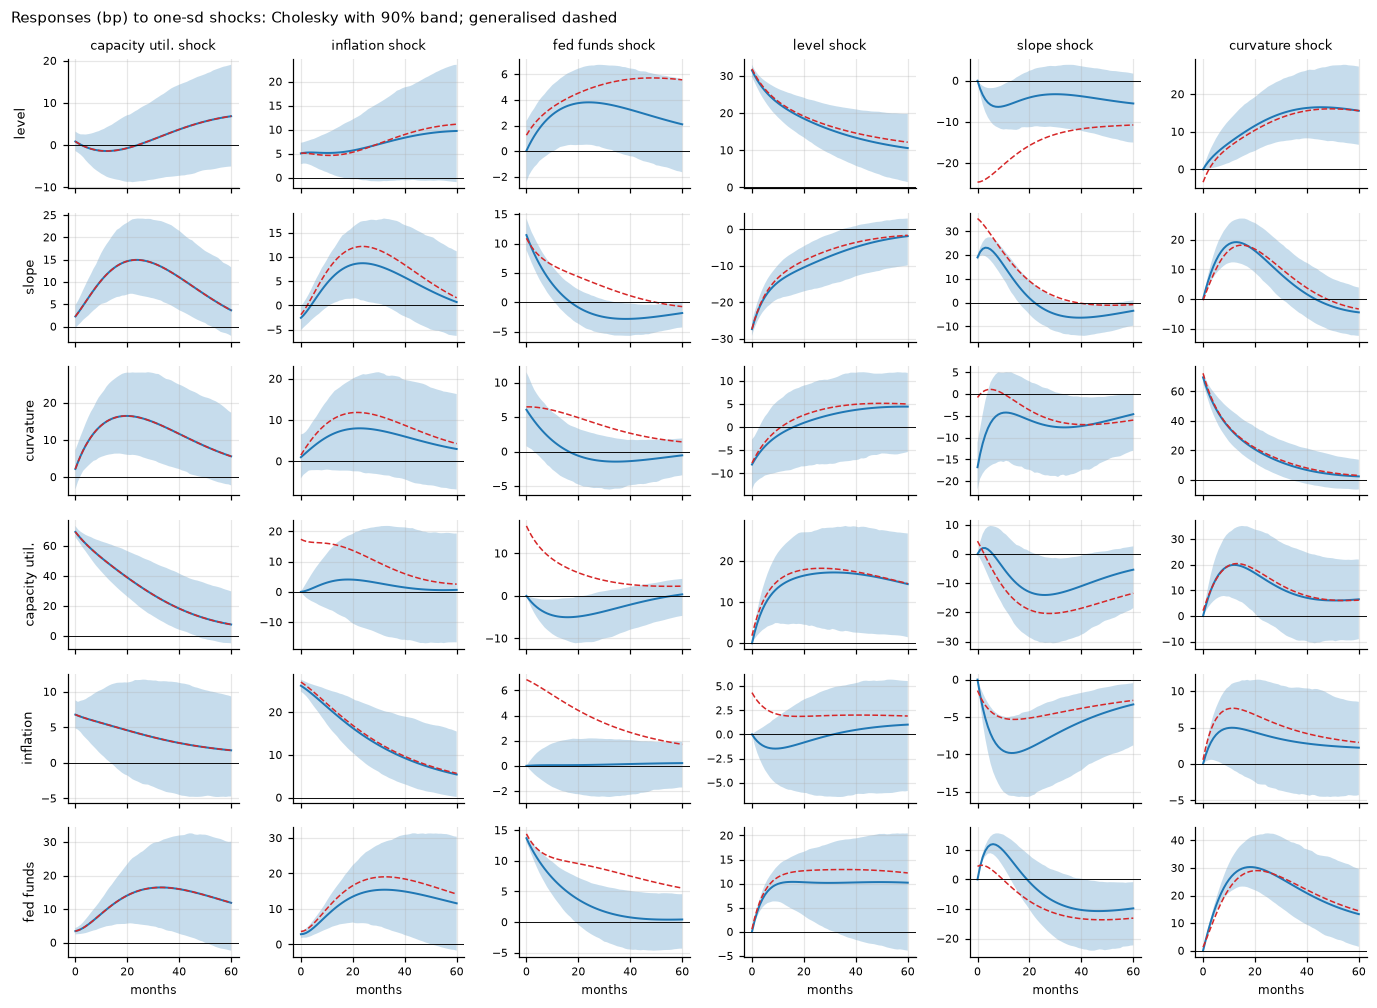

In [5]:
HOR = 60
draws = {kind: irf.irf_draws(fits["full"], data, horizon=HOR, kind=kind, n_draws=1000, info=infos["full"])
         for kind in ("cholesky", "generalized")}
print({k: f"{d.n_rejected} of 1000 draws explosive, discarded" for k, d in draws.items()})

def irf_grid(fit, draws, responders=None, shocks=None, title=""):
    names = fit.state_names
    order = [names[i] for i in irf.resolve_order(names)]
    responders, shocks = responders or names, shocks or order
    ch, gen = draws["cholesky"], draws.get("generalized")
    lo, hi = ch.band(0.9)
    fig, axes = plt.subplots(len(responders), len(shocks), figsize=(2.1 * len(shocks), 1.55 * len(responders)),
                             sharex=True, squeeze=False)
    h = np.arange(ch.point.shape[0])
    for r, resp in enumerate(responders):
        i = names.index(resp)
        for c, shock in enumerate(shocks):
            j, ax = names.index(shock), axes[r, c]
            ax.fill_between(h, 100 * lo[:, i, j], 100 * hi[:, i, j], alpha=0.25, lw=0)
            ax.plot(h, 100 * ch.point[:, i, j], lw=1.3)
            if gen is not None:
                ax.plot(h, 100 * gen.point[:, i, j], lw=1, ls="--", color="C3")
            ax.axhline(0, color="k", lw=0.6)
            ax.tick_params(labelsize=7)
            if r == 0: ax.set_title(f"{LABEL[shock]} shock", fontsize=8.5)
            if c == 0: ax.set_ylabel(LABEL[resp], fontsize=8.5)
            if r == len(responders) - 1: ax.set_xlabel("months", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontsize=10)
    fig.tight_layout()

irf_grid(fits["full"], draws, title="Responses (bp) to one-sd shocks: Cholesky with 90% band; generalised dashed")

**Reading the grid** (rows respond, columns are shocks):

- **Curve → macro (lower-left block).** A curvature shock raises the fed funds
  rate (+28 bp after 12 months) and capacity utilisation. A level shock
  raises both with a delay. A slope shock (short rates up relative to long)
  lowers inflation by about 10 bp at 6–24 months and later lowers activity
  and the policy rate. This is the pattern DRA (2006) report: the curve
  anticipates the macro economy and the Fed.
- **Macro → curve (upper-right block).** An inflation shock raises the level
  by about 5 bp. An activity shock raises the slope and curvature (the short
  and medium end) but not the level. A policy-rate shock moves the short end
  on impact (slope +11 bp, curvature +6 bp) and fades within a year. The
  level barely moves (+3–4 bp).
- **Policy.** Fed funds respond to activity and inflation shocks with the
  expected sign, building over two years. A policy shock lowers capacity
  utilisation slightly (−0.05 pp at 12 months), which is significant but
  small.
- **Robustness.** The generalised responses (dashed) agree with Cholesky for
  the macro → curve and curve → macro links above. They differ where shocks
  are correlated on impact. A generalised slope shock carries a −25 bp
  level move with it (shock correlation −0.77). A generalised fed funds
  shock *raises* capacity utilisation and inflation, because it includes
  the macro news the Fed reacts to within the month. That second difference
  is why a recursive identification is needed to talk about policy
  shocks at all.

### Responses of the whole curve

The yield response at maturity τ is the Nelson–Siegel loadings times the
factor responses. Below: the curve's response to each macro shock on impact
and after 6, 12 and 24 months, with 90% bands at 12 months.

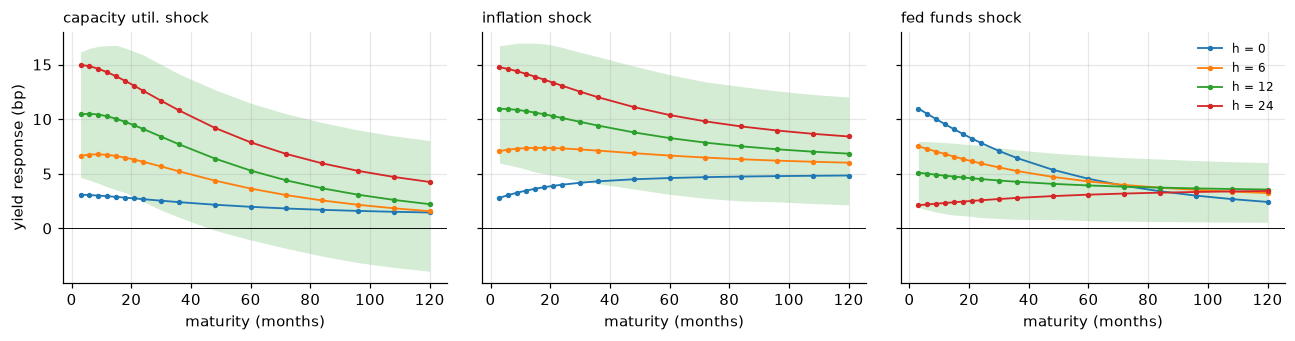

In [6]:
fit = fits["full"]
names = fit.state_names
tau = maturities_from_columns(fit.yield_columns)
Z = ns_loadings(tau, fit.params.lam)
yr = irf.yield_responses(draws["cholesky"].point, Z)
yr_draws = np.array([irf.yield_responses(d, Z) for d in draws["cholesky"].draws])
lo12, hi12 = np.quantile(yr_draws[:, 12], [0.05, 0.95], axis=0)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, shock in zip(axes, MACRO):
    j = names.index(shock)
    ax.fill_between(tau, 100 * lo12[:, j], 100 * hi12[:, j], alpha=0.2, lw=0, color="C2")
    for hh, c in zip([0, 6, 12, 24], ["C0", "C1", "C2", "C3"]):
        ax.plot(tau, 100 * yr[hh, :, j], marker="o", ms=2.5, lw=1.2, color=c, label=f"h = {hh}")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{LABEL[shock]} shock", loc="left", fontsize=10); ax.set_xlabel("maturity (months)")
axes[0].set_ylabel("yield response (bp)"); axes[-1].legend(fontsize=8, frameon=False); fig.tight_layout()

## 4. Variance decompositions

The share of each variable's h-month forecast-error variance due to each
orthogonalised shock (Cholesky ordering as above). If macro shocks explained
much of the factors' forecast variance at 6–12 months, the macro model should
forecast better at those horizons.

Share of the factors' forecast error variance due to the three macro shocks (%)


,h=1,h=6,h=12,h=24,h=60
level,3.0,3.0,4.0,6.0,13.0
slope,11.0,9.0,10.0,20.0,33.0
curvature,1.0,2.0,5.0,12.0,21.0


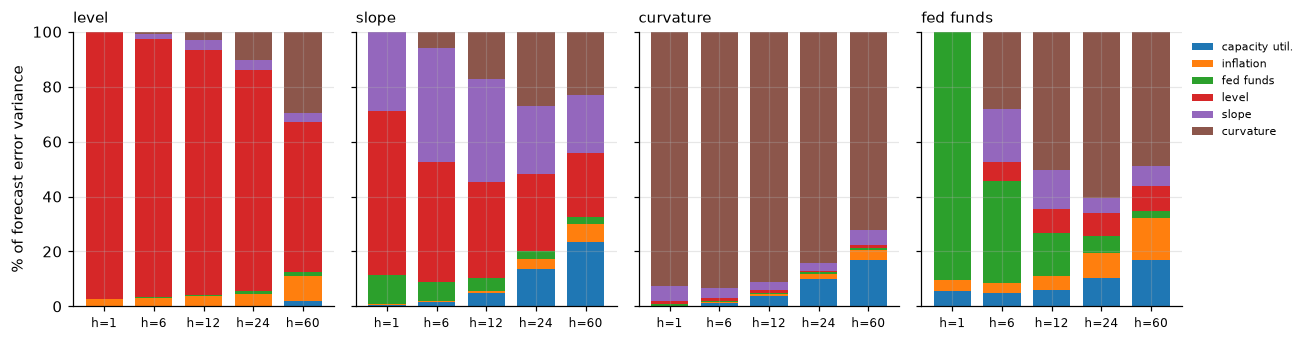

In [7]:
order_names = [names[i] for i in irf.resolve_order(names)]
vd = irf.variance_decomposition(fit.params.A, fit.params.Q, 60, irf.resolve_order(names))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, var in zip(axes, ["level", "slope", "curvature", "policy_rate"]):
    i = names.index(var)
    tab = pd.DataFrame({f"h={h}": 100 * vd[h - 1, i] for h in (1, 6, 12, 24, 60)}, index=names).loc[order_names].T
    tab.rename(columns=LABEL).plot.bar(stacked=True, ax=ax, width=0.75, legend=False)
    ax.set_title(LABEL[var], loc="left", fontsize=10); ax.tick_params(axis="x", rotation=0, labelsize=8)
axes[0].set_ylabel("% of forecast error variance")
axes[-1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1), loc="upper left"); fig.tight_layout()

macro_share = pd.DataFrame({f"h={h}": {LABEL[v]: 100 * vd[h - 1, names.index(v), 3:].sum()
                                         for v in ["level", "slope", "curvature"]} for h in (1, 6, 12, 24, 60)})
print("Share of the factors' forecast error variance due to the three macro shocks (%)")
macro_share.round(0)

## 5. Policy-rate-only model

Out of sample (§6), the version with only the fed funds rate is the macro
model that forecasts best. Its responses to a policy shock and its curve →
policy links are very close to the full model's. Dropping capacity
utilisation and inflation loses little of the joint dynamics, and saves 32
parameters.

140 of 1000 draws explosive, discarded


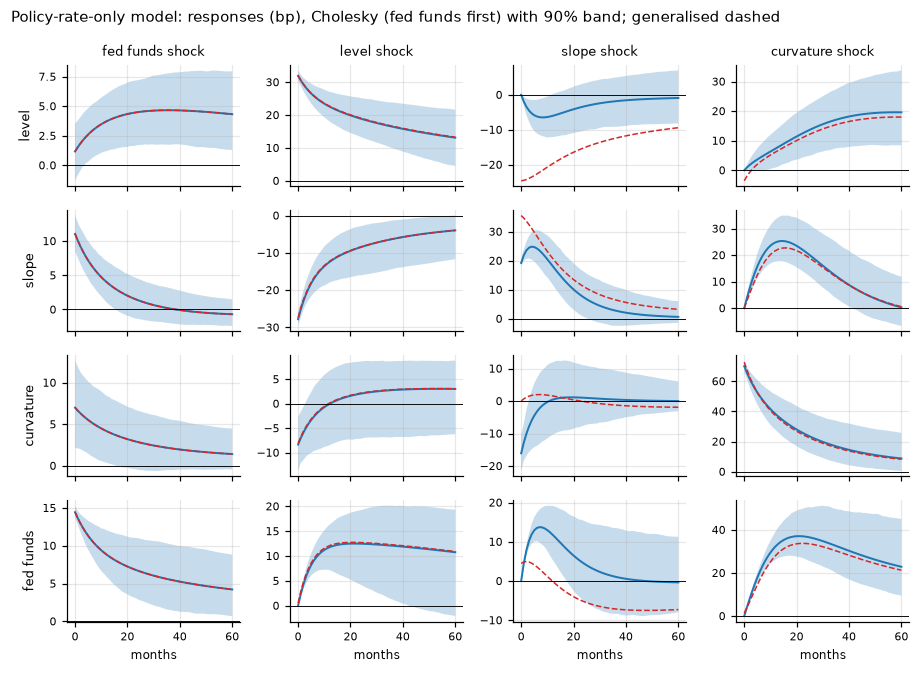

In [8]:
fr = fits["policy rate only"]
draws_r = {"cholesky": irf.irf_draws(fr, data[fr.columns], horizon=HOR, n_draws=1000, info=infos["policy rate only"]),
           "generalized": irf.irf_draws(fr, data[fr.columns], horizon=HOR, kind="generalized", n_draws=1000,
                                        info=infos["policy rate only"])}
print(f"{draws_r['cholesky'].n_rejected} of 1000 draws explosive, discarded")
irf_grid(fr, draws_r, title="Policy-rate-only model: responses (bp), Cholesky (fed funds first) with 90% band; generalised dashed")

## 6. Out of sample: does macro information help forecast?

Recursive backtest, USD, estimation from 1985, origins from 2000-01,
parameters re-estimated every 12 months, forecasts from **filtered** states,
macro data **as known at each origin** (§1). The forecasts are produced by

```bash
python -m yck backtest --ccy USD                                      # yields only
python -m yck backtest --ccy USD --macro                              # full DRA
python -m yck backtest --ccy USD --macro --macro-vars policy_rate     # policy rate only
python -m yck backtest --ccy USD --macro --shrink 0.01 0.03 0.1 0.3   # shrunk DRA
```

and written to `data/results/` (git-ignored). If any are missing, the whole
standard grid is run once here (`ensure_results`: one longest-first pool,
~1.5 min for all three currencies on 8 cores).

The comparisons:

- **Macro vs yields-only** is nested (zero cross-links give yields-only), so
  it uses **Clark–West**: one-sided, positive = macro better.
- **Every model vs forwards** is non-nested, so it uses **Diebold–Mariano**
  with the HLN correction: two-sided.

In [9]:
SPECS = {  # name: (file tag, macro variables, shrinkage tau)
    "yields only": ("lamfixed", None, None),
    "full DRA": ("macro_lamfixed", MACRO, None),
    "DRA shrunk τ=0.01": ("macro_shrink0.01_lamfixed", MACRO, 0.01),
    "policy rate only": ("macro-policy_rate_lamfixed", ["policy_rate"], None),
}

ensure_results(["USD"], ROOT / "data", CONFIG)
load_fc = lambda tag: {h: pd.read_parquet(RESULTS / f"fc_USD_kalman_{tag}_h{h}.parquet") for h in H}
fc = {name: load_fc(tag) for name, (tag, _, _) in SPECS.items()}
fc["random walk"] = random_walk_forecasts(y, H, FIRST_ORIGIN)
fc["forwards"] = forward_forecasts(pd.read_parquet(ROOT / "data/processed/curves_ext_USD.parquet"), y.columns,
                                   H, FIRST_ORIGIN)
SHOW = ["3m", "12m", "24m", "60m", "120m"]

In [10]:
def by_h(h, benchmark):
    t = dm_table({n: fc[n][h] for n in fc}, benchmark, y, h, SHOW)
    return t.xs("cell", axis=1, level=1).T

print("RMSE relative to the random walk (< 1 = better; stars: DM test vs RW, two-sided 10/5/1%)")
pd.concat({f"h = {h}": by_h(h, "random walk") for h in (6, 12)})

RMSE relative to the random walk (< 1 = better; stars: DM test vs RW, two-sided 10/5/1%)


3m   12m     24m      60m    120m
h = 6  yields only         0.87  0.98    1.05    1.11*    1.06
       full DRA            0.92  1.04   1.12*  1.20***  1.18**
       DRA shrunk τ=0.01   0.88  0.98    1.03    1.09*    1.07
       policy rate only    0.82  0.95    1.04     1.11    1.08
       forwards           0.83*  0.97    1.04    1.08*   1.06*
h = 12 yields only         0.91  1.00    1.07     1.19    1.14
       full DRA            1.00  1.10  1.19**   1.29**   1.26*
       DRA shrunk τ=0.01   0.92  0.99    1.05     1.14    1.11
       policy rate only    0.88  0.98    1.07     1.17    1.11
       forwards            0.89  0.97    1.03     1.13   1.12*

In [11]:
def cw_table(h, small="yields only"):
    rows = {}
    for name in ["full DRA", "DRA shrunk τ=0.01", "policy rate only"]:
        row = {}
        for col in SHOW:
            idx = y.index.intersection(fc[small][h].index).intersection(fc[name][h].index)
            a = y.loc[idx, col]
            fs, fl = fc[small][h].loc[idx, col], fc[name][h].loc[idx, col]
            cw = clark_west(fs - a, fl - a, fs, fl, h)
            ratio = np.sqrt(((fl - a) ** 2).mean() / ((fs - a) ** 2).mean())
            p = cw["pvalue"]
            row[col] = f"{ratio:.2f}" + ("***" if p < .01 else "**" if p < .05 else "*" if p < .1 else "")
        rows[name] = row
    return pd.DataFrame(rows).T

print("RMSE relative to yields-only Kalman; stars: Clark-West, one-sided, macro better at 10/5/1%")
pd.concat({f"h = {h}": cw_table(h) for h in H})

RMSE relative to yields-only Kalman; stars: Clark-West, one-sided, macro better at 10/5/1%


3m      12m    24m     60m    120m
h = 1  full DRA              1.06   1.02**   1.03    1.01    1.04
       DRA shrunk τ=0.01     1.02   1.00**   1.00  0.99**    1.01
       policy rate only      1.04  0.98***   1.00    1.00    1.02
h = 6  full DRA             1.06*    1.06*   1.08    1.07    1.11
       DRA shrunk τ=0.01    1.01*    0.99*  0.99*   0.98*    1.00
       policy rate only   0.95***   0.97**  0.99*    1.00    1.02
h = 12 full DRA              1.09     1.10   1.11    1.09    1.10
       DRA shrunk τ=0.01     1.01     0.99   0.98   0.96*   0.97*
       policy rate only    0.96**    0.98*   0.99    0.99  0.98**

In [12]:
print("RMSE relative to forwards (< 1 = beats the market; stars: DM vs forwards, two-sided 10/5/1%)")
pd.concat({f"h = {h}": by_h(h, "forwards").drop(index="random walk") for h in H})

RMSE relative to forwards (< 1 = beats the market; stars: DM vs forwards, two-sided 10/5/1%)


3m   12m     24m      60m     120m
h = 1  yields only        1.21***  1.00    1.00  1.04***  1.12***
       full DRA           1.28***  1.02    1.03  1.05***  1.17***
       DRA shrunk τ=0.01  1.23***  1.00    1.00   1.04**  1.14***
       policy rate only   1.25***  0.98    1.00  1.05***  1.14***
h = 6  yields only           1.05  1.01    1.01     1.03     1.00
       full DRA              1.11  1.07    1.09    1.11*     1.11
       DRA shrunk τ=0.01     1.06  1.00    1.00     1.01     1.00
       policy rate only      0.99  0.98    1.00     1.03     1.02
h = 12 yields only           1.03  1.03    1.04     1.05     1.01
       full DRA              1.13  1.13  1.15**     1.14     1.12
       DRA shrunk τ=0.01     1.04  1.02    1.02     1.01     0.99
       policy rate only      0.99  1.01    1.03     1.04     0.99

## 7. Takeaways

- **Real-time data matter for activity, not much for inflation.** Capacity
  utilisation is revised by about 1 pp on average (up to 2.8 pp), which is a
  quarter of its standard deviation. Core PCE inflation moves by about
  0.2 pp. ALFRED also withdraws the PCE history for two weeks around the
  2003 comprehensive revision; the panel then uses the last complete vintage.
- **In sample, the curve leads the macro economy more than the reverse**,
  as in DRA (2006). Curve shocks explain much of the policy rate's forecast
  variance (three quarters at 12 months; curvature alone half), and a flatter curve (slope
  shock) predicts lower inflation. Macro shocks explain only 1–11% of the
  x, rising to 13–33% at 5 years.
  Inflation shocks lift the whole curve by about 5 bp, and activity and
  policy shocks move mostly the short end.
- **That explains the out-of-sample result.** At the 6–12-month horizons
  that matter for forecasting, macro shocks explain little of the curve,
  and what the curve does not already contain is mostly the policy rate.
  So the only macro model that beats yields-only (Clark–West) is the
  policy-rate-only model, at the short end: 3m RMSE −4% to −5% at
  h = 6, 12. The full 6-state model has 80 parameters and is significantly
  worse than the random walk from 2y out. Shrinkage brings it back to
  yields-only accuracy but no further.
- **Nothing beats the forward curve.** The best model (policy rate only)
  has RMSE ratios to forwards of 0.98–1.04 at h = 6, 12, never
  significant. At h = 1 every model is significantly worse than forwards
  at 3m and from 5y out. The market already prices what these macro
  variables say about the next year of yields.
- **Next:** the same analysis for EUR and GBP (README §8, step 7), and then
  the trading evaluation (step 8), where the question becomes whether the
  small short-end gain survives as P&L against carry.